In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
df = pd.read_csv('/content/house_price_linear_regression.csv')

print(df.head())


   area_sqft  bedrooms  age_years  distance_to_city_km  price_lakh
0        685         2          1                  2.3       54.01
1        720         3          2                  3.1       53.91
2        755         4          3                  3.9       62.52
3        790         1          4                  4.7       44.52
4        825         2          5                  5.5       53.42


In [9]:
print(df.head())

   area_sqft  bedrooms  age_years  distance_to_city_km  price_lakh
0        685         2          1                  2.3       54.01
1        720         3          2                  3.1       53.91
2        755         4          3                  3.9       62.52
3        790         1          4                  4.7       44.52
4        825         2          5                  5.5       53.42


In [10]:
print("Dataset Shape:", df.shape)
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Shape: (100, 5)
Number of Rows: 100
Number of Columns: 5


In [11]:
print("Column Names:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

Column Names:
Index(['area_sqft', 'bedrooms', 'age_years', 'distance_to_city_km',
       'price_lakh'],
      dtype='object')

Data Types:
area_sqft                int64
bedrooms                 int64
age_years                int64
distance_to_city_km    float64
price_lakh             float64
dtype: object


In [34]:
# Define target and input features
y = df["price_lakh"]

# Simple Linear Regression
X_simple = df[["area_sqft"]]

In [35]:
# Input features
X = df[
    ["area_sqft", "bedrooms",
     "age_years", "distance_to_city_km"]
]

# Target variable
y = df["price_lakh"]

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

Input Features:
   area_sqft  bedrooms  age_years  distance_to_city_km
0        685         2          1                  2.3
1        720         3          2                  3.1
2        755         4          3                  3.9
3        790         1          4                  4.7
4        825         2          5                  5.5

Target Variable:
0    54.01
1    53.91
2    62.52
3    44.52
4    53.42
Name: price_lakh, dtype: float64


In [24]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
area_sqft              0
bedrooms               0
age_years              0
distance_to_city_km    0
price_lakh             0
dtype: int64


In [25]:
print("Descriptive Statistics:")
print(df.describe())

Descriptive Statistics:
         area_sqft    bedrooms   age_years  distance_to_city_km  price_lakh
count   100.000000  100.000000  100.000000           100.000000  100.000000
mean   1562.700000    2.500000   12.000000            12.380000   76.519100
std     523.246673    1.123666    7.247431             6.988128   23.635866
min     685.000000    1.000000    0.000000             1.500000   31.630000
25%    1114.500000    1.750000    6.000000             6.300000   56.865000
50%    1561.500000    2.500000   12.000000            11.900000   74.925000
75%    2008.500000    3.250000   18.000000            18.300000   97.070000
max    2473.000000    4.000000   24.000000            24.700000  122.560000


In [26]:
# Simple Linear Regression data
X_simple = df[["area_sqft"]]

# Multiple Linear Regression data
X_multiple = df[
    ["area_sqft", "bedrooms",
     "age_years", "distance_to_city_km"]
]

# Split Simple Regression data
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

# Split Multiple Regression data
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multiple, y, test_size=0.2, random_state=42
)

In [27]:
# Create model
simple_model = LinearRegression()

# Train model
simple_model.fit(X_train_s, y_train_s)

# Make predictions
simple_pred = simple_model.predict(X_test_s)

print("Simple Linear Regression Predictions:")
print(simple_pred)

Simple Linear Regression Predictions:
[ 91.30961317  46.20222273  71.91260457 106.76076348 105.30702622
  98.03833992  72.32795807  86.94840138  54.38468674  39.34888992
  66.01458483  84.45628037  76.27381635  88.81749215 101.9841982
  45.16383897  80.63502814  82.0887654   57.29216126  85.91001763]


In [28]:
# Create model
multiple_model = LinearRegression()

# Train model
multiple_model.fit(X_train_m, y_train_m)

# Make predictions
multiple_pred = multiple_model.predict(X_test_m)

print("Multiple Linear Regression Predictions:")
print(multiple_pred)

Multiple Linear Regression Predictions:
[ 79.06624964  44.94375409  77.009997   105.52514823  99.42484942
  92.33774013  67.8174486   84.17973796  64.31554338  49.59985105
  66.28916436 107.13673133  71.89650868 102.02324301 119.83118495
  50.58666153  82.65145372  88.75175252  53.10175626  89.82264541]


In [29]:
def evaluate_model(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(actual, predicted)
    return [mae, mse, rmse, r2]

# Evaluate Simple Linear Regression
simple_results = evaluate_model(y_test_s, simple_pred)
# Evaluate Multiple Linear Regression
multiple_results = evaluate_model(y_test_m, multiple_pred)
# Display comparison
results = pd.DataFrame(
    [simple_results, multiple_results],
    columns=["MAE", "MSE", "RMSE", "R2 Score"],
    index=[
        "Simple Linear Regression",
        "Multiple Linear Regression"
    ]
)
print(results)

                                 MAE         MSE       RMSE  R2 Score
Simple Linear Regression    7.940356  104.044407  10.200216  0.752572
Multiple Linear Regression  1.930878    5.152011   2.269804  0.987748


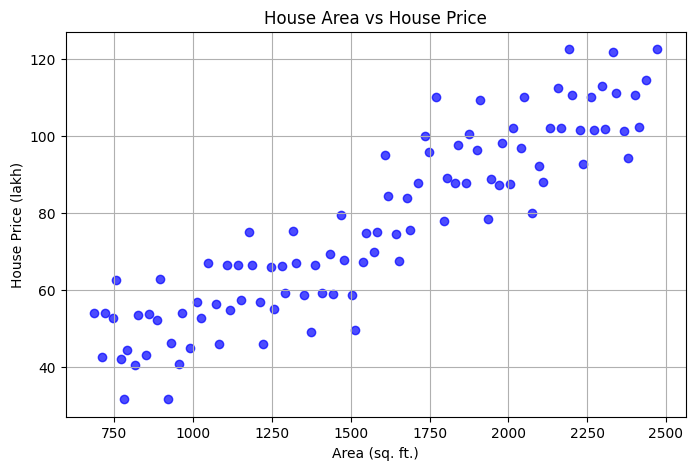

In [30]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["area_sqft"],
    df["price_lakh"],
    color="blue",
    alpha=0.7
)

plt.xlabel("Area (sq. ft.)")
plt.ylabel("House Price (lakh)")
plt.title("House Area vs House Price")

plt.grid(True)
plt.show()

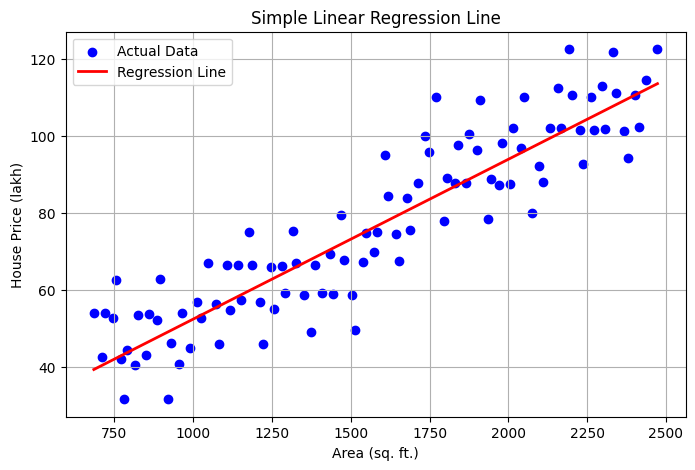

In [31]:
plt.figure(figsize=(8, 5))
plt.scatter(
    df["area_sqft"],
    df["price_lakh"],
    color="blue",
    label="Actual Data"
)
x_line = np.linspace(
    df["area_sqft"].min(),
    df["area_sqft"].max(),
    100
)
y_line = simple_model.predict(
    pd.DataFrame({"area_sqft": x_line})
)
plt.plot(x_line,y_line,color="red",linewidth=2,label="Regression Line"
)
plt.xlabel("Area (sq. ft.)")
plt.ylabel("House Price (lakh)")
plt.title("Simple Linear Regression Line")
plt.legend()
plt.grid(True)
plt.show()

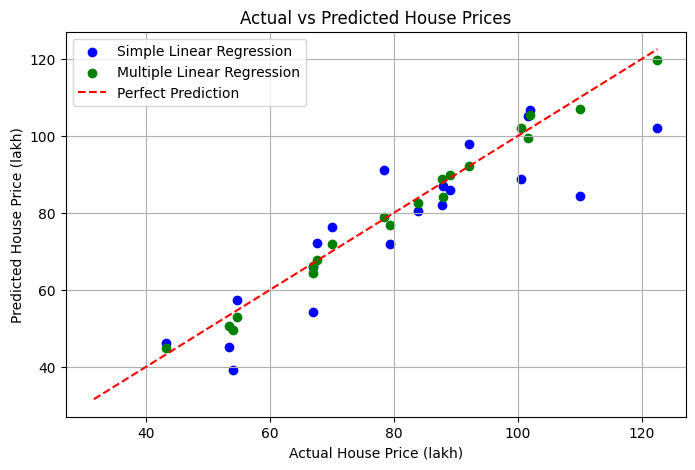

In [32]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test_s,simple_pred,color="blue",label="Simple Linear Regression")
plt.scatter(y_test_m, multiple_pred, color="green", label="Multiple Linear Regression")
min_value = min(y.min(), simple_pred.min(),multiple_pred.min())
max_value = max(
    y.max(),
    simple_pred.max(),
    multiple_pred.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual House Price (lakh)")
plt.ylabel("Predicted House Price (lakh)")
plt.title("Actual vs Predicted House Prices")

plt.legend()
plt.grid(True)
plt.show()

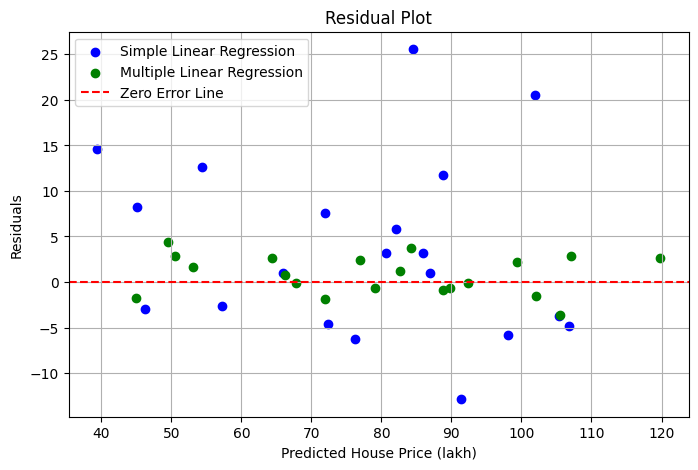

In [33]:
# Calculate residuals
simple_residuals = y_test_s - simple_pred
multiple_residuals = y_test_m - multiple_pred
plt.figure(figsize=(8, 5))
plt.scatter( simple_pred, simple_residuals, color="blue", label="Simple Linear Regression")
plt.scatter(multiple_pred, multiple_residuals, color="green", label="Multiple Linear Regression")
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Zero Error Line"
)

plt.xlabel("Predicted House Price (lakh)")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.legend()
plt.grid(True)
plt.show()